# CBE 130 Lab 3: Linear Algebra for Chemical Engineering Models

Linear algebra provides the language for coupled process models, material balances, parameter estimation, and dynamic systems. In this lab, we first reinforce the second-order ODE methods from Lab 2 and then use vectors, matrices, linear systems, and eigenvalues to organize and interpret chemical engineering calculations.

## Learning Objectives

- Compare forward Euler, RK2, RK4, and `solve_ivp` solutions for second-order ODEs.
- Implement basic vector and matrix operations with NumPy.
- Interpret matrix-vector multiplication as a linear transformation.
- Solve square and overdetermined linear systems and assess their residuals.
- Compute and validate eigenvalues and eigenvectors for simple process matrices.

## Setup

Run this cell once before working through the lab. NumPy supports the array and linear algebra calculations, Matplotlib creates the plots, and SciPy provides `solve_ivp`.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

np.set_printoptions(precision=3, suppress=True)
print(f"NumPy version: {np.__version__}")

NumPy version: 2.0.2


## Part 1: Review of Second-Order ODE Methods

Second-order models appear in process control, mixing, and transport problems. Each equation below is rewritten as a system of two first-order equations before applying the numerical methods from Lab 2.

### Question 1.1

Consider the linear, second-order, nonhomogeneous model

$$
y''+3y'+2y=5e^x, \qquad y(0)=0, \qquad y'(0)=1, \qquad 0\leq x\leq5.
$$

Use the characteristic equation to find the homogeneous solution and use undetermined coefficients to find the particular solution. Then use a step size of $h=1$ to compute forward Euler, RK2 midpoint, and RK4 solutions. Use `solve_ivp` on the same fixed $x$ grid, plot all four numerical solutions with the analytical solution, and report the RMSE and maximum absolute error for the three methods implemented by hand. Here, $x$ is the independent model coordinate and $y$ is a dimensionless response.

The characteristic roots are $-1$ and $-2$. A particular solution of the form $Ae^x$ gives $A=5/6$. Applying the initial conditions gives

$$
y(x)=-\frac{3}{2}e^{-x}+\frac{2}{3}e^{-2x}+\frac{5}{6}e^x.
$$

For a state vector $Y_n=[y_n,y'_n]^T$, the update formulas are

$$Y_{n+1}=Y_n+hF(x_n,Y_n) \qquad \text{(forward Euler)},$$

$$k_1=F(x_n,Y_n),\quad k_2=F\left(x_n+\frac{h}{2},Y_n+\frac{h}{2}k_1\right),\quad Y_{n+1}=Y_n+hk_2 \qquad \text{(RK2)},$$

and

$$k_1=F(x_n,Y_n),\quad k_2=F\left(x_n+\frac{h}{2},Y_n+\frac{h}{2}k_1\right),$$
$$k_3=F\left(x_n+\frac{h}{2},Y_n+\frac{h}{2}k_2\right),\quad k_4=F(x_n+h,Y_n+hk_3),$$
$$Y_{n+1}=Y_n+\frac{h}{6}(k_1+2k_2+2k_3+k_4) \qquad \text{(RK4)}.$$

Euler: RMSE = 2.215e+01
Euler: maximum absolute error = 5.059e+01
RK2: RMSE = 8.111e+00
RK2: maximum absolute error = 1.872e+01


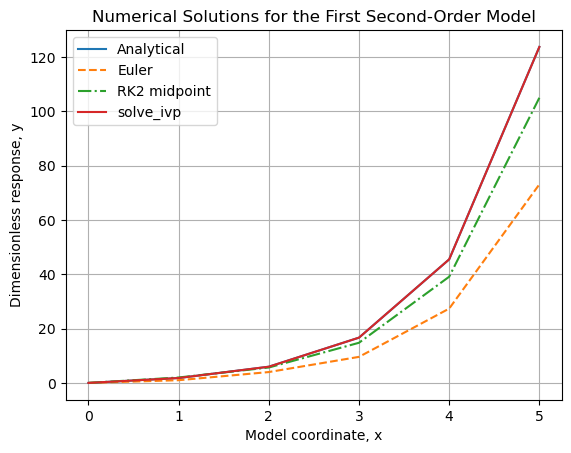

In [7]:
def F(x_current, y_n):
    y_current = y_n[0]
    y_prime_current = y_n[1]
    dy_dx = y_prime_current
    dy_prime_dx = -3.0 * y_prime_current - 2.0 * y_current + 5.0 * np.exp(x_current)
    return np.array([dy_dx, dy_prime_dx])

def y_exact_1(x_values):
    return (-1.5 * np.exp(-x_values)
            + (2.0 / 3.0) * np.exp(-2.0 * x_values)
            + (5.0 / 6.0) * np.exp(x_values))

def integrate_numerical(method, x_current, y_current, x_step):
    if method == "Euler":
        k1_values = F(x_current, y_current)
        next_state_values = y_current + x_step * k1_values
    elif method == "RK2":
        k1_values = F(x_current, y_current)
        midpoint_state_values = y_current + 0.5 * x_step * k1_values
        k2_values = F(x_current + 0.5 * x_step, midpoint_state_values)
        next_state_values = y_current + x_step * k2_values
    else:
        raise ValueError("method must be Euler, RK2, or RK4")
    
    return next_state_values

x_initial = 0.0
x_final = 5.0
x_step = 1.0
x_values = np.arange(x_initial, x_final + x_step / 2.0, x_step)
initial_state_values = np.array([0.0, 1.0])
method_names = ["Euler", "RK2"]
method_results = {}

for method_name in method_names:
    y_values = np.zeros((len(x_values), 2))
    y_values[0] = initial_state_values
    for index in range(len(x_values) - 1):
        y_values[index + 1] = integrate_numerical(
            method_name, x_values[index], y_values[index], x_step
        )
    method_results[method_name] = y_values

solve_ivp_solution = solve_ivp(
    F,
    (x_initial, x_final),
    initial_state_values,
    t_eval=x_values,
)
solve_ivp_values = solve_ivp_solution.y.T
y_exact_values = y_exact_1(x_values)

for method_name in method_names:
    y_numerical_values = method_results[method_name][:, 0]
    error_values = y_numerical_values - y_exact_values
    root_mean_square_error = np.sqrt(np.mean(error_values**2))
    maximum_absolute_error = np.max(np.abs(error_values))
    print(f"{method_name}: RMSE = {root_mean_square_error:.3e}")
    print(f"{method_name}: maximum absolute error = {maximum_absolute_error:.3e}")

plt.figure()
plt.plot(x_values, y_exact_values, label="Analytical")
plt.plot(x_values, method_results["Euler"][:, 0], "--", label="Euler")
plt.plot(x_values, method_results["RK2"][:, 0], "-.", label="RK2 midpoint")
plt.plot(x_values, solve_ivp_values[:, 0], label="solve_ivp")
plt.title("Numerical Solutions for the First Second-Order Model")
plt.xlabel("Model coordinate, x")
plt.ylabel("Dimensionless response, y")
plt.legend()
plt.grid(True)
plt.show()

### Question 1.2

Consider a second forced process-response model,

$$
y''+6y'+0.2y=6\cos x-0.8\sin x+0.18x,\qquad y(0)=3.85,\qquad y'(0)=-0.66,\qquad 0\leq x\leq10.
$$

Find the homogeneous and particular solutions, apply the initial conditions, and compare forward Euler, RK2 midpoint, RK4, and `solve_ivp` with the analytical solution. Use $h=0.05$, plot the response, and report the RMSE and maximum absolute error for every numerical method. The response $y$ is dimensionless.

The characteristic roots are

$$r_{1,2}=\frac{-6\pm\sqrt{35.2}}{2},$$

and a suitable particular solution is $y_p=\sin x+0.9x-27$. The constants in $y_h=C_1e^{r_1x}+C_2e^{r_2x}$ are obtained from the two initial conditions in the code below.

Euler: RMSE = 2.723e-02
Euler: maximum absolute error = 4.656e-02
RK2: RMSE = 3.470e-04
RK2: maximum absolute error = 1.809e-03
RK4: RMSE = 1.519e-06
RK4: maximum absolute error = 8.233e-06
solve_ivp: RMSE = 5.271e-05
solve_ivp: maximum absolute error = 1.402e-04


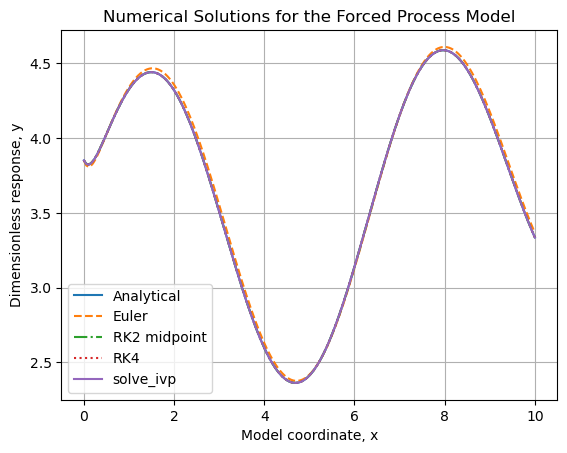

In [9]:
def response_derivatives_2(x_current, state_values):
    y_current = state_values[0]
    y_prime_current = state_values[1]
    forcing_value = (
        6.0 * np.cos(x_current) - 0.8 * np.sin(x_current) + 0.18 * x_current
    )
    dy_dx = y_prime_current
    dy_prime_dx = -6.0 * y_prime_current - 0.2 * y_current + forcing_value
    return np.array([dy_dx, dy_prime_dx])

discriminant = 36.0 - 0.8
r1 = (-6.0 + np.sqrt(discriminant)) / 2.0
r2 = (-6.0 - np.sqrt(discriminant)) / 2.0
coefficient_matrix = np.array([[1.0, 1.0], [r1, r2]])
constant_values = np.array([30.85, -2.56])
homogeneous_coefficients = np.linalg.solve(coefficient_matrix, constant_values)
C1 = homogeneous_coefficients[0]
C2 = homogeneous_coefficients[1]

def y_exact_2(x_values):
    return (
        C1 * np.exp(r1 * x_values)
        + C2 * np.exp(r2 * x_values)
        + np.sin(x_values)
        + 0.9 * x_values
        - 27.0
    )

def numerical_update_2(method, x_current, state_values, x_step):
    if method == "Euler":
        k1_values = response_derivatives_2(x_current, state_values)
        next_state_values = state_values + x_step * k1_values
    elif method == "RK2":
        k1_values = response_derivatives_2(x_current, state_values)
        k2_values = response_derivatives_2(
            x_current + 0.5 * x_step, state_values + 0.5 * x_step * k1_values
        )
        next_state_values = state_values + x_step * k2_values
    elif method == "RK4":
        k1_values = response_derivatives_2(x_current, state_values)
        k2_values = response_derivatives_2(
            x_current + 0.5 * x_step, state_values + 0.5 * x_step * k1_values
        )
        k3_values = response_derivatives_2(
            x_current + 0.5 * x_step, state_values + 0.5 * x_step * k2_values
        )
        k4_values = response_derivatives_2(
            x_current + x_step, state_values + x_step * k3_values
        )
        next_state_values = state_values + (x_step / 6.0) * (
            k1_values + 2.0 * k2_values + 2.0 * k3_values + k4_values
        )
    else:
        raise ValueError("method must be Euler, RK2, or RK4")
    return next_state_values

x_initial = 0.0
x_final = 10.0
x_step = 0.05
x_values = np.arange(x_initial, x_final + x_step / 2.0, x_step)
initial_state_values = np.array([3.85, -0.66])
method_results = {}

method_names = ["Euler", "RK2", "RK4"]

for method_name in method_names:
    state_values = np.zeros((len(x_values), 2))
    state_values[0] = initial_state_values
    for index in range(len(x_values) - 1):
        state_values[index + 1] = numerical_update_2(
            method_name, x_values[index], state_values[index], x_step
        )
    method_results[method_name] = state_values

solve_ivp_solution = solve_ivp(
    response_derivatives_2,
    (x_initial, x_final),
    initial_state_values,
    t_eval=x_values,
)
solve_ivp_values = solve_ivp_solution.y.T
y_exact_values = y_exact_2(x_values)

for method_name in method_names:
    y_numerical_values = method_results[method_name][:, 0]
    error_values = y_numerical_values - y_exact_values
    root_mean_square_error = np.sqrt(np.mean(error_values**2))
    maximum_absolute_error = np.max(np.abs(error_values))
    print(f"{method_name}: RMSE = {root_mean_square_error:.3e}")
    print(f"{method_name}: maximum absolute error = {maximum_absolute_error:.3e}")

solve_ivp_error_values = solve_ivp_values[:, 0] - y_exact_values
solve_ivp_rmse = np.sqrt(np.mean(solve_ivp_error_values**2))
solve_ivp_maximum_error = np.max(np.abs(solve_ivp_error_values))
print(f"solve_ivp: RMSE = {solve_ivp_rmse:.3e}")
print(f"solve_ivp: maximum absolute error = {solve_ivp_maximum_error:.3e}")

plt.figure()
plt.plot(x_values, y_exact_values, label="Analytical")
plt.plot(x_values, method_results["Euler"][:, 0], "--", label="Euler")
plt.plot(x_values, method_results["RK2"][:, 0], "-.", label="RK2 midpoint")
plt.plot(x_values, method_results["RK4"][:, 0], ":", label="RK4")
plt.plot(x_values, solve_ivp_values[:, 0], label="solve_ivp")
plt.title("Numerical Solutions for the Forced Process Model")
plt.xlabel("Model coordinate, x")
plt.ylabel("Dimensionless response, y")
plt.legend()
plt.grid(True)
plt.show()

## Part 2: Vectors

A vector is an ordered list of numbers. In chemical engineering, a vector might store concentrations of several species, temperatures measured at several locations, or flow rates in several process streams. Important operations include vector addition, scalar multiplication, the dot product, and the vector norm.

### Question 2.1

The vectors $\mathbf{u}=(2,-1,3)$ and $\mathbf{v}=(1,4,0)$ represent two normalized three-component process states. Compute $\mathbf{u}+\mathbf{v}$, $2.5\mathbf{v}$, the dot product $\mathbf{u}\cdot\mathbf{v}$, and the norm of each vector. Print each result.

In [11]:
u = np.array([2.0, -1.0, 3.0])
v = np.array([1.0, 4.0, 0.0])

vector_sum = u + v
scaled_vector = 2.5 * v
dot_product = np.dot(u, v)
u_norm = np.linalg.norm(u)
v_norm = np.linalg.norm(v)

print(f"u = {u}")
print(f"v = {v}")
print(f"u + v = {vector_sum}")
print(f"2.5v = {scaled_vector}")
print(f"u dot v = {dot_product:.3f}")
print(f"Norm of u = {u_norm:.3f}")
print(f"Norm of v = {v_norm:.3f}")

u = [ 2. -1.  3.]
v = [1. 4. 0.]
u + v = [3. 3. 3.]
2.5v = [ 2.5 10.   0. ]
u dot v = -2.000
Norm of u = 3.742
Norm of v = 4.123


### Question 2.2

Let $\mathbf{a}=(3,1,-2)$ and $\mathbf{b}=(-1,2,2)$ represent two three-sensor response patterns. Compute their sum, dot product, and angle in degrees. The angle satisfies

$$
\cos\theta=\frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\lVert\mathbf{b}\rVert}.
$$

Print all three results; the angle is dimensionless but should be reported in degrees.

In [12]:
a = np.array([3.0, 1.0, -2.0])
b = np.array([-1.0, 2.0, 2.0])

sum_ab = a + b
dot_ab = np.dot(a, b)
cosine_angle = dot_ab / (np.linalg.norm(a) * np.linalg.norm(b))
angle_degrees = np.degrees(np.arccos(np.clip(cosine_angle, -1.0, 1.0)))

print(f"a + b = {sum_ab}")
print(f"a dot b = {dot_ab:.3f}")
print(f"Angle between a and b = {angle_degrees:.3f} degrees")

a + b = [2. 3. 0.]
a dot b = -5.000
Angle between a and b = 116.451 degrees


### Question 2.3

For $\mathbf{u}=(2,-1,4)$ and $\mathbf{v}=(1,3,-2)$, compute $\mathbf{u}+\mathbf{v}$, $3\mathbf{u}-2\mathbf{v}$, $\mathbf{u}\cdot\mathbf{v}$, $\lVert\mathbf{u}\rVert$, and the angle between the vectors in radians and degrees. Print the calculated values.

In [14]:
u = np.array([2.0, -1.0, 4.0])
v = np.array([1.0, 3.0, -2.0])

vector_sum = u + v
linear_combination = 3.0 * u - 2.0 * v
dot_product = np.dot(u, v)
u_norm = np.linalg.norm(u)
v_norm = np.linalg.norm(v)
cosine_angle = dot_product / (u_norm * v_norm)
angle_radians = np.arccos(np.clip(cosine_angle, -1.0, 1.0))
angle_degrees = np.degrees(angle_radians)

print(f"u + v = {vector_sum}")
print(f"3u - 2v = {linear_combination}")
print(f"u dot v = {dot_product:.3f}")
print(f"Norm of u = {u_norm:.3f}")
print(f"Norm of v = {v_norm:.3f}")
print(f"Angle = {angle_radians:.3f} radians")
print(f"Angle = {angle_degrees:.3f} degrees")

u + v = [3. 2. 2.]
3u - 2v = [ 4. -9. 16.]
u dot v = -9.000
Norm of u = 4.583
Norm of v = 3.742
Angle = 2.123 radians
Angle = 121.661 degrees


## Part 3: Matrices and Linear Transformations

A matrix acts as a linear function that maps one vector to another. Its columns show where the basis vectors map. Depending on its entries, a two-dimensional matrix can scale, shear, rotate, or reflect a vector.

### Question 3.1

Let

$$
A=\begin{bmatrix}
1 & 2 \\
3 & 0 \\
0 & 1
\end{bmatrix},
\qquad
\mathbf{x}=\begin{bmatrix}
2 \\
-1
\end{bmatrix},
\qquad
B=\begin{bmatrix}
0 & 1 & 1 \\
1 & 1 & 0
\end{bmatrix}.
$$

Compute $A\mathbf{x}$, $AB$, and $A^T$. These operations can represent combining inlet-stream properties into outlet measurements. Print each result and its shape.

In [15]:
A = np.array([[1.0, 2.0],
              [3.0, 0.0],
              [0.0, 1.0]])
x = np.array([2.0, -1.0])
B = np.array([[0.0, 1.0, 1.0],
              [1.0, 1.0, 0.0]])

matrix_vector_product = A @ x
matrix_product = A @ B
matrix_transpose = A.T

print(f"A @ x =\n{matrix_vector_product}")
print(f"Shape of A @ x = {matrix_vector_product.shape}")
print(f"A @ B =\n{matrix_product}")
print(f"Shape of A @ B = {matrix_product.shape}")
print(f"Transpose of A =\n{matrix_transpose}")

A @ x =
[ 0.  6. -1.]
Shape of A @ x = (3,)
A @ B =
[[2. 3. 1.]
 [0. 3. 3.]
 [1. 1. 0.]]
Shape of A @ B = (3, 3)
Transpose of A =
[[1. 3. 0.]
 [2. 0. 1.]]


### Question 3.2

For

$$
A=\begin{bmatrix}
2 & -1 \\
0 & 3
\end{bmatrix},
\qquad
\mathbf{x}=\begin{bmatrix}
1 \\
2
\end{bmatrix}.
$$

compute $A\mathbf{x}$. Then choose two $2\times2$ matrices $B$ and $C$ and verify numerically that matrix multiplication is not commutative by showing $BC\neq CB$. Print all results.

In [16]:
A = np.array([[2.0, -1.0],
              [0.0, 3.0]])
x = np.array([1.0, 2.0])
B = np.array([[0.0, 1.0],
              [0.0, 0.0]])
C = np.array([[0.0, 0.0],
              [1.0, 0.0]])

matrix_vector_product = A @ x
BC = B @ C
CB = C @ B
products_are_equal = np.allclose(BC, CB)

print(f"A @ x = {matrix_vector_product}")
print(f"B @ C =\n{BC}")
print(f"C @ B =\n{CB}")
print(f"Is B @ C equal to C @ B? {products_are_equal}")

A @ x = [0. 6.]
B @ C =
[[1. 0.]
 [0. 0.]]
C @ B =
[[0. 0.]
 [0. 1.]]
Is B @ C equal to C @ B? False


## Part 4: Linear Systems

Chemical engineering balances are often written as $A\mathbf{x}=\mathbf{b}$. A full-rank square system has one solution. An overdetermined system can be approximated with least squares, while a rank-deficient system does not contain enough independent equations for a unique solution.

### Question 4.1

First, solve the square system $A\mathbf{x}=\mathbf{b}$ below and compute its residual. Next, treat $C\mathbf{p}\approx\mathbf{d}$ as four experimental measurements used to estimate two model parameters. Compute the least-squares parameter vector, predictions, and residuals. All values are normalized, so no units are assigned.

$$
A=\begin{bmatrix}
3 & 2 & -1 \\
2 & -2 & 4 \\
-1 & 0.5 & -1
\end{bmatrix},
\qquad
\mathbf{b}=\begin{bmatrix}
1 \\
-2 \\
0
\end{bmatrix}.
$$

$$
C=\begin{bmatrix}
1 & 1 \\
1 & 2 \\
1 & 3 \\
1 & 4
\end{bmatrix},
\qquad
\mathbf{d}=\begin{bmatrix}
2.2 \\
2.9 \\
3.7 \\
4.1
\end{bmatrix}.
$$

In [21]:
A = np.array([[3.0, 2.0, -1.0],
              [2.0, -2.0, 4.0],
              [-1.0, 0.5, -1.0]])
b = np.array([1.0, -2.0, 0.0])
x = np.linalg.solve(A, b)
square_system_residual = A @ x - b

print(f"Square-system solution = {x}")
print(f"Square-system residual = {square_system_residual}")

C = np.array([[1.0, 1.0],
              [1.0, 2.0],
              [1.0, 3.0],
              [1.0, 4.0]])
d = np.array([2.2, 2.9, 3.7, 4.1])
least_squares_result = np.linalg.lstsq(C, d)
parameter_values = least_squares_result[0]
prediction_values = C @ parameter_values
least_squares_residual = prediction_values - d

print(f"Least-squares parameter values = {parameter_values}")
print(f"Predictions = {prediction_values}")
print(f"Least-squares residuals = {least_squares_residual}")

Square-system solution = [ 1. -2. -2.]
Square-system residual = [0. 0. 0.]
Least-squares parameter values = [1.6  0.65]
Predictions = [2.25 2.9  3.55 4.2 ]
Least-squares residuals = [ 0.05  0.   -0.15  0.1 ]


### Question 4.2

Construct the rank-deficient system shown below, whose rows are linearly dependent. Compute the rank of $A$, attempt to solve $A\mathbf{y}=\mathbf{b}$, and explain why a unique solution is unavailable. Then compute one least-squares solution and verify $A\mathbf{y}_{LS}$.

$$
A=\begin{bmatrix}
1 & 2 & 3 \\
2 & 4 & 6 \\
3 & 6 & 9
\end{bmatrix},
\qquad
\mathbf{b}=\begin{bmatrix}
1 \\
2 \\
3
\end{bmatrix}.
$$

In [23]:
A = np.array([[1.0, 2.0, 3.0],
              [2.0, 4.0, 6.0],
              [3.0, 6.0, 9.0]])
b = np.array([1.0, 2.0, 3.0])
matrix_rank = np.linalg.matrix_rank(A)
print(f"Rank of A = {matrix_rank}")

try:
    y = np.linalg.solve(A, b)
    print(f"Direct solution = {y}")
except np.linalg.LinAlgError as error_message:
    print(f"Direct solve failed because the matrix is singular: {error_message}")

least_squares_result = np.linalg.lstsq(A, b)
y_least_squares = least_squares_result[0]
reconstructed_b = A @ y_least_squares
print(f"One least-squares solution = {y_least_squares}")
print(f"A @ y_least_squares = {reconstructed_b}")
print(f"Because rank(A) is less than 3, the system has no unique solution.")

Rank of A = 1
Direct solution = [0.  0.5 0. ]
One least-squares solution = [0.071 0.143 0.214]
A @ y_least_squares = [1. 2. 3.]
Because rank(A) is less than 3, the system has no unique solution.


### Question 4.3

A simplified two-unit material balance produces

$$
2x+y=5,\qquad -x+3y=4.
$$

Write this system in matrix form, solve for the normalized stream variables $x$ and $y$, and verify the result by calculating $A\mathbf{x}$.

In [ ]:
A = np.array([[2.0, 1.0],
              [-1.0, 3.0]])
b = np.array([5.0, 4.0])
stream_values = np.linalg.solve(A, b)
verification_values = A @ stream_values

print(f"Solution [x, y] = {stream_values}")
print(f"A @ [x, y] = {verification_values}")
print(f"Target vector b = {b}")